
# Customer Churn and Retention Prediction


In this project, I will work on a customer churn prediction problem using Machine Learning.

Customer churn means when a customer stops using a company's services. Losing customers can affect a company's revenue and business growth. So, it is important for a company to understand why customers leave and identify customers who may leave in the future.

In this project, I will use the IBM Telco Customer Churn dataset to analyse customer behaviour and identify the factors that may lead to customer churn.

Project Objective

- Understand customer data and analyse customer behaviour.
- Identify the main factors responsible for customer churn.
- Build Machine Learning models to predict whether a customer is likely to leave or stay.
- Evaluate model performance using different classification metrics.
- Find useful insights that can help businesses improve customer retention.

Dataset Information

The dataset contains information about 7,043 telecom customers and has 21 columns.

It includes information such as customer tenure, services used, contract type, monthly charges, total charges, payment methods and churn status.

The target variable is Churn, which tells us whether a customer has left the company or is still using its services.

Tools and Libraries

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook


In [1]:
## Importing important libreries .
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [63]:
from pathlib import Path

csv_name = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

possible_paths = [
    Path(csv_name),
    Path("data") / csv_name,
    Path("../data") / csv_name
]

data_path = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if data_path is None:
    raise FileNotFoundError(f"Dataset not found: {csv_name}")

df = pd.read_csv(data_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [64]:
##checking prerequisites before getting into operations
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
# Check missing values
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [10]:
# Check duplicate customer IDs
df["customerID"].duplicated().sum()

np.int64(0)

In [11]:
# Check blank values in TotalCharges TotalCharges contains some blank strings so thats why we checking some blank values
(df["TotalCharges"].astype(str).str.strip() == "").sum()

np.int64(11)

In [12]:
## now understanding our target values
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [13]:
# Check churn percentage
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [14]:
### Investigating Blank Values in TotalCharges
blank_total_charges = df["TotalCharges"].astype(str).str.strip().eq("")
# Display the selected customer records
df.loc[blank_total_charges,["customerID","tenure","MonthlyCharges","TotalCharges","Churn","Contract"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn,Contract
488,4472-LVYGI,0,52.55,,No,Two year
753,3115-CZMZD,0,20.25,,No,Two year
936,5709-LVOEQ,0,80.85,,No,Two year
1082,4367-NUYAO,0,25.75,,No,Two year
1340,1371-DWPAZ,0,56.05,,No,Two year
3331,7644-OMVMY,0,19.85,,No,Two year
3826,3213-VVOLG,0,25.35,,No,Two year
4380,2520-SGTTA,0,20.00,,No,Two year
5218,2923-ARZLG,0,19.70,,No,One year
6670,4075-WKNIU,0,73.35,,No,Two year



During the missing value investigation, I found
11 blank values in the TotalCharges column.

After examining these records, I noticed that
all 11 customers have a tenure value of 0.
Their MonthlyCharges values are available,
and all are currently marked as non-churned.

This suggests that these customers may have
recently joined the company and have not
accumulated any total charges yet.

Instead of directly removing these records,
I decided to investigate the reason behind
the missing values before choosing a
suitable treatment.

In [15]:
#now convert those missing values with 0 cause filling this values with mean mode will not get us better reprasentation so will fill 0 to those missing values 
# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors = "coerce"
)
# Verify missing values
df["TotalCharges"].isnull().sum()

#now fill vaules with "0"
df["TotalCharges"] = df["TotalCharges"].fillna(0)

#now check again missing values it should give 0
df["TotalCharges"].isnull().sum()

np.int64(0)

In [16]:
#now check all columns again to perform further operations
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [17]:
#Now check any duplicates values if its have some so we have to remove them.
df.duplicated().sum()

np.int64(0)

In [18]:
## Noww check some categorical values 
categorical_cols = [
    col for col in df.select_dtypes(include="object").columns
    if col !="customerID"
]
##Display unique value and this frequency
for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Column: Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Column: Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Column: PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Column: MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Column: InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Column: OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Column: OnlineBackup
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

Column: DeviceProtection
DeviceProtection
No                     3095
Yes                    2422
No internet service   

In [19]:
df["SeniorCitizen"].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

SeniorCitizen Column Investigation

The SeniorCitizen column is stored as an integer
data type, so it was not included in our automatic
object-type categorical column selection.

However, it represents two customer categories:

 0: Not a senior citizen,
 1: Senior citizen

After checking its distribution, I found that
5,901 customers (83.78%) are not senior citizens
and 1,142 customers (16.22%) are senior citizens.

Therefore, I identified SeniorCitizen as a
binary categorical feature despite its numerical
data type.

In [20]:
## NOW check numerical columns
numerical_cols = df[["tenure","MonthlyCharges","TotalCharges"]].describe()
print(numerical_cols)

            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000       18.250000      0.000000
25%       9.000000       35.500000    398.550000
50%      29.000000       70.350000   1394.550000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000


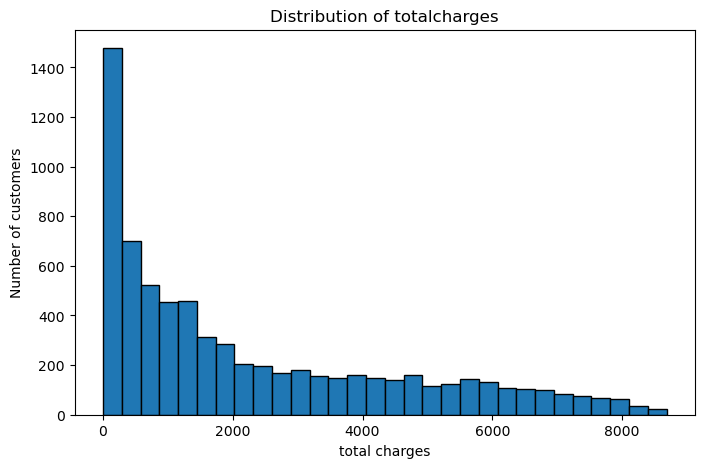

In [21]:
# plot the histogram to check the numerical cols
plt.figure(figsize=(8,5))
plt.hist(df["TotalCharges"],bins = 30,edgecolor = "black")

plt.title("Distribution of totalcharges")
plt.xlabel("total charges")
plt.ylabel("Number of customers")

plt.show()

 Most customers are concentrated in the lower
  TotalCharges ranges.
- The distribution is positively (right) skewed.
- Some customers have significantly higher
  TotalCharges values than others.

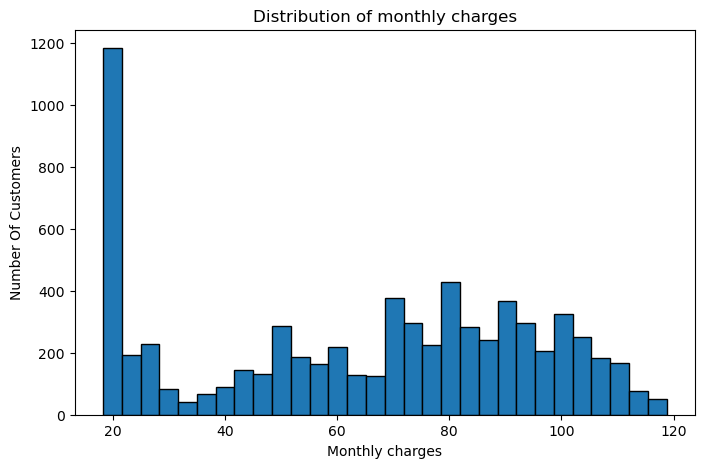

In [22]:
plt.figure(figsize = (8,5))
plt.hist(df["MonthlyCharges"],bins = 30,edgecolor = "black")

plt.title("Distribution of monthly charges")
plt.xlabel("Monthly charges")
plt.ylabel("Number Of Customers")

plt.show()

- Customer monthly charges vary across the dataset.
- Noticeable concentrations appear in different
  monthly charge ranges.
- The mean (64.76) is lower than the median (70.35).
- The distribution has slight negative skewness.

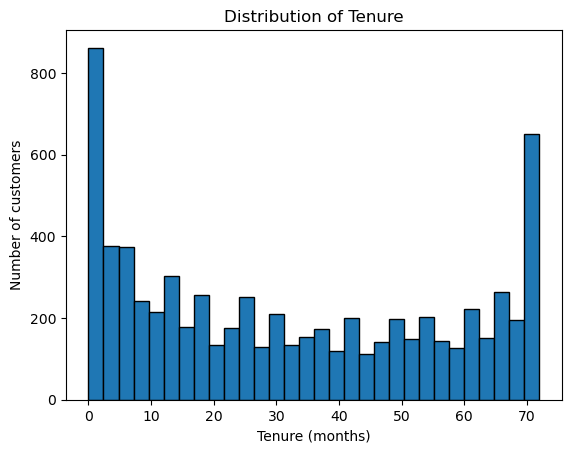

In [23]:
plt.figure()
plt.hist(df["tenure"],bins = 30,edgecolor = "black")
plt.title("Distribution of Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.show()

In [24]:
#Question: Are customers with month-to-month contracts more likely to leave the company?
# so in this we will check contract is related to churn rate?

so by this crosstab we will get to know how many customers left month tot month and years wise so in this case month to month customer left many as compared to year wise 

In [25]:
#now we clculate percentage wise churn rate so that we get to know better.
contract_churn_percentage = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize = "index"
)*100
print(contract_churn_percentage)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


so by this crosstab we will get to know how many customers left month tot month and years wise so in this case month to month customer left many as compared to year wise

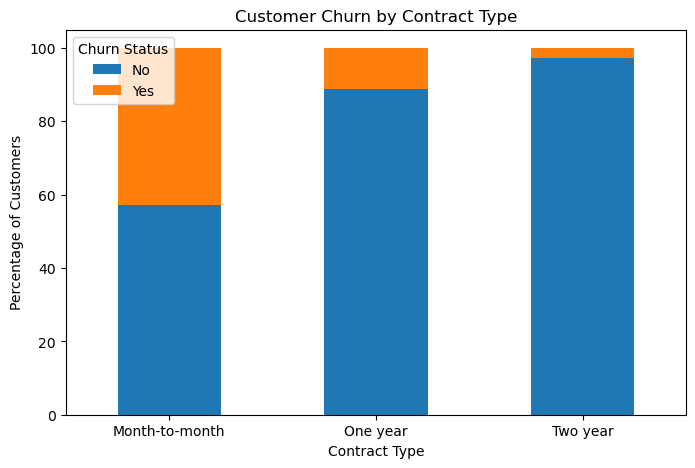

In [26]:
#now create stack bar plot for contrac and churn to get know via visulizaition
contract_churn_percentage.plot(
    kind = "bar",
    stacked = "True",
    figsize = (8,5)
)
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn Status")
plt.show()

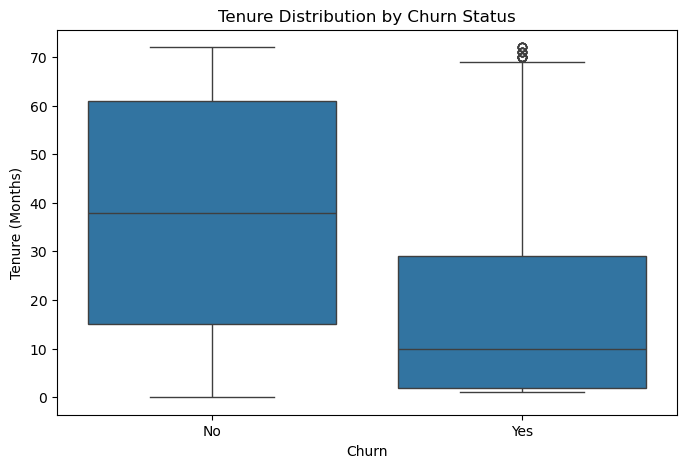

In [27]:
#Are customers who have stayed with the company for a shorter period more likely to churn?
plt.figure(figsize=(8, 5))

sns.boxplot(x="Churn", y="tenure", data=df)

plt.title("Tenure Distribution by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()


In [28]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


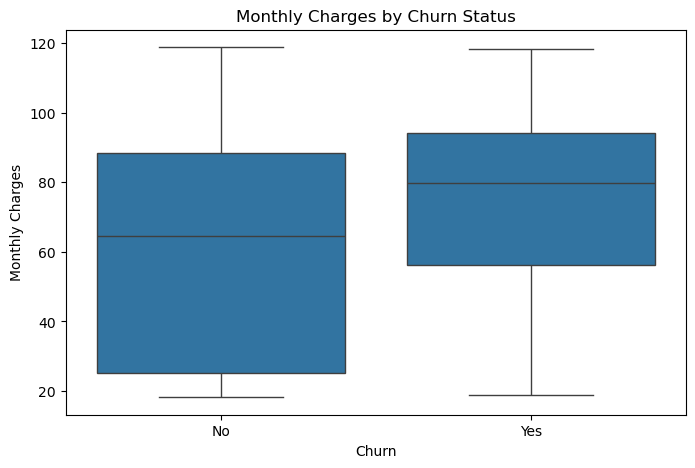

In [29]:
#Do customers who pay higher monthly charges have a different churn rate from customers who pay lower monthly charges?
plt.figure(figsize=(8, 5))

sns.boxplot(x="Churn", y="MonthlyCharges", data=df)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [30]:
# Compare monthly charges between churn groups
df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
Churn,,,
No,5174,61.265124,64.425
Yes,1869,74.441332,79.650


now make this preprocessing of data and get fratures(X) and target values.(y)

In [31]:
X = df.drop(columns=["customerID","Churn"])
y = df["Churn"].map({"No":0,"Yes":1})  # so here we have values in no and yes format as text so we need them into numerical format so this will assien no to 0 and yes is 1
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [32]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [33]:
#now we Identify categorical and numerical features
# Identify categorical features
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

categorical_features.append("SeniorCitizen")

# Identify continuous numerical features
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen']
Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Recreate features and target from original dataset
X = df.drop(columns=["customerID", "Churn"]).copy()
y = df["Churn"].map({"No": 0, "Yes": 1})

# 2. Identify feature types
categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

categorical_features.append("SeniorCitizen")

numerical_features = [
    "tenure", "MonthlyCharges", "TotalCharges"
]

# 3. Split the dataset again
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)

# 5. Transform the datasets
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# 6. Verify
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (5634, 46)
Testing: (1409, 46)


In [35]:
#Now create our first dummy classifier model to check and evaluate other models
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,classification_report

# Create baseline model
dummy_model = DummyClassifier(strategy="most_frequent")

# Train baseline
dummy_model.fit(X_train, y_train)

# Make predictions
y_pred_dummy = dummy_model.predict(X_test)

# Evaluate baseline
print("Accuracy:", accuracy_score(y_test, y_pred_dummy))
print(classification_report(y_test, y_pred_dummy))

Accuracy: 0.7345635202271115
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [36]:
#now we will train and build linear regressions model to test and evaluate against dummy model

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

#create logistic regression
log_model = LogisticRegression(max_iter=1000)

#train the model
log_model.fit(X_train,y_train)

#predicton testing data
log_prediction = log_model.predict(X_test)

#Now evaluate the logistic model
print("Accuracy:\n",accuracy_score(y_test,log_prediction))
print("\nClassififcation_report: \n ",classification_report(y_test,log_prediction))
print("confusion_Matrix: \n",confusion_matrix(y_test,log_prediction))

Accuracy:
 0.8055358410220014

Classififcation_report: 
                precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

confusion_Matrix: 
 [[926 109]
 [165 209]]




The Logistic Regression model got 80.55% accuracy, which is better than our baseline model (73.46%).

From the confusion matrix:

 926 customers were correctly predicted as staying.
 109 customers were predicted to leave, but they stayed.
 165 customers were predicted to stay, but they left.
 209 customers were correctly predicted as leaving.

So, Logistic Regression is doing better than our baseline model. But it is still missing some customers who are leaving, so we need to improve it further.

In [38]:
#Now we are training Random Forest model to check which model gives better results ,against the lgistic model

In [39]:
#Imporing the libreries
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

#create the random forest
rf_model = RandomForestClassifier(
    n_estimators = 100,
    random_state = 42
)
#Train the rf model
rf_model.fit(X_train,y_train)

#Predictiong on test data
rf_prediction = rf_model.predict(X_test)

#evaluate the model
print("Accuracy_score: ",accuracy_score(y_test,rf_prediction))
print("\nClassification_report: \n",classification_report(y_test,rf_prediction))
print("Confusion_matrix: \n",confusion_matrix(y_test,rf_prediction))

Accuracy_score:  0.7842441447835344

Classification_report: 
               precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409

Confusion_matrix: 
 [[926 109]
 [195 179]]


so here in this case rf model does not gives us better results than logistic classifier it gives 78.42% which is low than logistic model(80.55%).
Logistic Regression gives better accuracy.



It finds more customers who leave.



Its precision and F1-score are also higher.



Random Forest has not performed better, even though it uses 100 decision trees.


In [41]:
#dataset has more customers who stayed than customers who left 
#Logistic Regression to give more importance to the smaller class using class_weight="balanced".

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

log_model_balanced = LogisticRegression(
    max_iter = 1000,
    class_weight = "balanced"
)
log_model_balanced.fit(X_train,y_train)

log_balanced_prediction = log_model_balanced.predict(X_test)

print("Accuracy_score: ",accuracy_score(y_test,log_balanced_prediction))
print("\nClassification_report: \n",classification_report(y_test,log_balanced_prediction))
print("\nConfusion_matrix: \n",confusion_matrix(y_test,log_balanced_prediction))

Accuracy_score:  0.7381121362668559

Classification_report: 
               precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion_matrix: 
 [[747 288]
 [ 81 293]]


Balanced Logistic Regression is better at finding customers who leave, but it is less accurate overall and gives more false alerts.

In [47]:
#so one more model testing to get better rresult than previous one try with XGBoost model to check against logistic model.
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from xgboost import XGBClassifier
xgb = XGBClassifier(
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 3,
    random_state = 42,
    eval_metric = "logloss"
)

xgb.fit(X_train,y_train)

xgb_prediction = xgb.predict(X_test)

print("Accuracy_score: ",accuracy_score(y_test,xgb_prediction))
print("\n Classification_report: \n",classification_report(y_test,xgb_prediction))
print("Confusion_matrix: \n",confusion_matrix(y_test,xgb_prediction))


Accuracy_score:  0.8034066713981547

 Classification_report: 
               precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409

Confusion_matrix: 
 [[935 100]
 [177 197]]


In [60]:
#now compare all three models and chekc which one is better than another

from sklearn.metrics import precision_score, recall_score, f1_score

model_results = pd.DataFrame({
    "Model": ["Dummy", "Logistic Regression", "Random Forest", "Balanced Logistic Regression", "XGBoost"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_dummy),
        accuracy_score(y_test, log_prediction),
        accuracy_score(y_test, rf_prediction),
        accuracy_score(y_test,log_balanced_prediction),
        accuracy_score(y_test,xgb_prediction)
    ],

    "Churn Precision": [
        precision_score(y_test, y_pred_dummy, zero_division=0),
        precision_score(y_test, log_prediction),
        precision_score(y_test, rf_prediction),
        precision_score(y_test,log_balanced_prediction),
        precision_score(y_test,xgb_prediction)
    ],

    "Churn Recall": [
        recall_score(y_test, y_pred_dummy),
        recall_score(y_test, log_prediction),
        recall_score(y_test, rf_prediction),
        recall_score(y_test,log_balanced_prediction),
        recall_score(y_test,xgb_prediction)
    ],

    "Churn F1-score": [
        f1_score(y_test, y_pred_dummy),
        f1_score(y_test, log_prediction),
        f1_score(y_test, rf_prediction),
        f1_score(y_test,log_balanced_prediction),
        f1_score(y_test,xgb_prediction)
    ],
    
})

model_results.set_index("Model").mul(100).round(2)

,Accuracy,Churn Precision,Churn Recall,Churn F1-score
Model,,,,
Dummy,73.46,0.00,0.00,0.00
Logistic Regression,80.55,65.72,55.88,60.40
Random Forest,78.42,62.15,47.86,54.08
Balanced Logistic Regression,73.81,50.43,78.34,61.36
XGBoost,80.34,66.33,52.67,58.72


Logistic Regression has the highest accuracy.



Balanced Logistic Regression finds the most customers who leave.



XGBoost has the highest precision, but only slightly higher than standard Logistic Regression.



Random Forest has the lowest churn recall among these four models.

In [55]:
#now get the features names which is imp for xgb boost 
features_names = preprocessor.get_feature_names_out()

xgb_importance = pd.DataFrame({
    "Feature":features_names,
    "Importance":xgb.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by = "Importance",
    ascending = False
)
xgb_importance.head(10)

,Feature,Importance
32,cat__Contract_Month-to-month,0.515225
12,cat__InternetService_Fiber optic,0.114048
23,cat__TechSupport_No,0.070006
14,cat__OnlineSecurity_No,0.047003
39,cat__PaymentMethod_Electronic check,0.031741
43,num__tenure,0.020267
31,cat__StreamingMovies_Yes,0.019085
33,cat__Contract_One year,0.018409
26,cat__StreamingTV_No,0.018126
13,cat__InternetService_No,0.015887


Feature Importance – XGBoost

According to the XGBoost model, month-to-month contract is the most important feature for predicting customer churn, followed by fiber optic internet and tech support.

Other important features include online security, payment method and customer tenure.

This helps us understand which customer details the model uses most when predicting churn. However, these results do not prove that these features are the reasons customers leave.

## Customer Retention Recommendations

Based on the analysis, here are some steps the company can take to reduce customer churn:

1. Focus on month-to-month customers: These customers have a much higher churn rate than customers on one-year or two-year contracts. The company can offer suitable discounts or benefits to encourage longer contracts.

2. Support new customers: Customers who leave tend to have shorter tenures. The company can follow up with new customers, help them understand the services and solve any problems early.

3. Review monthly charges: Customers who left had higher average monthly charges than customers who stayed. The company can review pricing and offer suitable plans based on customer needs.

4. Improve customer support: Tech support and online security were among the important features in the model. The company can make these services easier to understand and access.

5. Review internet service experience: Fiber optic internet was also an important feature in the model. The company can check customer feedback and service issues to understand whether improvements are needed.


## Final Conclusion

In this project, I worked on analysing customer churn and building machine learning models to predict customers who are likely to leave.

I started by cleaning and preparing the data, followed by exploratory data analysis to understand customer behaviour and identify patterns related to churn.

I trained and compared Logistic Regression, Balanced Logistic Regression, Random Forest and XGBoost models. Among them, Logistic Regression achieved the highest accuracy of 80.55%, while Balanced Logistic Regression achieved the highest churn recall of 78.34%.

The analysis also showed that month-to-month contracts, fiber optic internet and tech support were some of the important features used by the XGBoost model to predict churn.

Overall, this project helped me apply classification techniques, evaluate different models and understand how machine learning can support businesses in identifying customers who may leave and planning better retention strategies.